# 02 · Damp risk model

**Goal:** estimate the probability that each of England's 2.86m social homes has a damp problem, using only open data.

**Why this approach.** The original plan was to train a classifier on English Housing Survey (EHS) microdata, where trained
surveyors record damp in individual homes. The UK Data Service declined access, so this notebook builds the model from the
survey's **published damp rates** instead:

1. **Published rates**: what the survey tells us, by building age, type, floor area and energy rating
2. **Why not just multiply them?**: overlapping characteristics would be double-counted
3. **Calibrated logistic model**: coefficients chosen so the model reproduces every published rate on the real mix of homes
4. **Validation**: leave-one-out, and breakdowns the model never saw, judged against a sampling-noise floor
5. **Scoring and targeting**: what the estimates say, and how useful they'd be for inspections

The code lives in `src/models/calibrate.py` (the model, unit-tested on synthetic data) and `src/models/fit_damp.py` (the
real fit). This notebook runs them and explains the results.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ORANGE, PERIWINKLE, GREY, INK = "#F07B2B", "#8E9BF5", "#9AA0A8", "#1B1D21"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
pd.set_option("display.precision", 2)

## 1. Published damp rates

EHS live tables DA5101 (by dwelling) and DA5102 (by area) give the % of **social rented** homes with any damp, recorded by
surveyors. Only 2022–2024 split out social renting. 2022 is partly modelled (COVID) and visibly lower, so the model uses the
**average of 2023 and 2024**.

In [2]:
rates = pd.read_parquet(ROOT / "data/interim/ehs_tables/damp_rates.parquet")
social = rates[(rates.tenure == "social_rented") & (rates.damp_type == "any")]
table = (social[social.breakdown.isin(["dwelling age", "dwelling type", "total usable floor area"])]
         .pivot_table(index=["breakdown", "category"], columns="year", values="rate", sort=False))
table

year                                                    2024   2023   2022
breakdown               category                                          
dwelling age            pre-1919                       13.20  12.86  16.42
                        1919-44                         8.74   8.88   6.95
                        1945-64                         9.35   9.65   7.58
                        1965-80                         6.15   6.16   2.80
                        1981-90                         5.43   3.39   2.08
                        post 1990                       2.91   2.68   2.09
dwelling type           end terrace                     6.78   6.59   5.21
                        mid terrace                     8.05   8.78   5.87
                        small terraced house            6.24   7.01   5.17
                        medium/large terraced house     8.43   8.50   5.90
                        all terrace                     7.58   7.93   5.61
                        semi-detached                   8.56   8.50   4.33
                        bungalow                        5.03   5.35   2.70
                        converted flat                  7.86   9.69  16.08
                        purpose built flat, low rise    6.16   5.66   5.51
                        purpose built flat, high rise   6.95   6.61   4.83
                        all houses                      7.40   7.63   4.76
                        all flats                       6.33   5.99   6.14
total usable floor area less than 50m2                  4.82   4.97   4.09
                        50 to 69m2                      7.81   7.22   4.91
                        70 to 89m2                      7.16   7.95   7.08
                        90 to 109m2                     9.49   6.78   3.36
                        110m2 or more                   5.85   9.59   8.91
                        all dwellings                   6.91   6.90   5.36

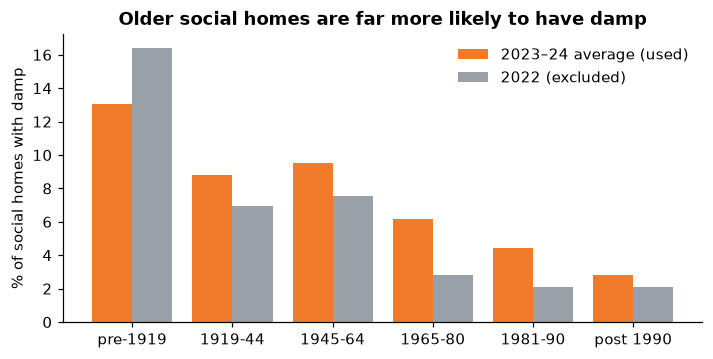

In [3]:
age = table.loc["dwelling age"].drop(index="all dwellings", errors="ignore")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(age))
ax.bar(x - 0.2, age[[2023, 2024]].mean(axis=1), 0.4, color=ORANGE, label="2023–24 average (used)")
ax.bar(x + 0.2, age[2022], 0.4, color=GREY, label="2022 (excluded)")
ax.set_xticks(x, age.index)
ax.set_ylabel("% of social homes with damp")
ax.set_title("Older social homes are far more likely to have damp")
ax.legend(frameon=False)
plt.show()

## 2. Why not just multiply the published rates?

A tempting shortcut: risk = national rate × (age ratio) × (energy-rating ratio) × … That assumes the characteristics are
independent. In the EPC data they clearly aren't: older homes are much more often poorly rated, so the same underlying
risk would be counted twice.

In [4]:
from src.models.fit_damp import FEATURES, load_cells, load_targets

cells = load_cells()
share_eg = (cells.assign(eg=cells.eer.eq("E-G") * cells.n).groupby("age")[["eg", "n"]].sum()
            .pipe(lambda d: 100 * d.eg / d.n).drop("unknown", errors="ignore"))
order = ["pre1919", "1919-1944", "1945-1964", "1965-1980", "1981-1990", "post1990"]
share_eg.loc[order].round(1).rename("% rated E–G").to_frame().T

age,pre1919,1919-1944,1945-1964,1965-1980,1981-1990,post1990
% rated E–G,8.7,4.2,4.3,3.8,2.7,1.7


**Pre-1919 homes are about five times as likely to be rated E–G as post-1990 homes.** A model that multiplies the separate
"old" and "poorly rated" effects would overstate risk for old, poorly rated homes.

## 3. Calibrated logistic model

The model is an additive logistic regression,

$$\text{logit}\,P(\text{damp}) = b_0 + b_{\text{age}} + b_{\text{type}} + b_{\text{area}} + b_{\text{rating}},$$

but there are no labelled homes to learn from. Instead, the coefficients are chosen so that, **applied to the real joint
mix of 2.86m EPC homes** (grouped into cells of identical homes), the predicted rate in every published category matches
the published rate. That's done by minimising the cross-entropy between published and predicted category rates. Because
the joint mix is real, the overlap shown above is accounted for automatically.

In [5]:
from src.models.calibrate import MarginModel, margin_table, summarise

fitted, held = load_targets()
overall = held.pop("_overall")
model = MarginModel(FEATURES).fit(cells, fitted)
p_cells = model.predict(cells)
print(f"{len(cells):,} cells of identical homes covering {cells.n.sum():,} homes")
print(f"Published overall rate {100 * overall:.1f}% · model mean {100 * np.average(p_cells, weights=cells.n):.1f}%")

35,229 cells of identical homes covering 2,855,846 homes
Published overall rate 6.9% · model mean 7.1%


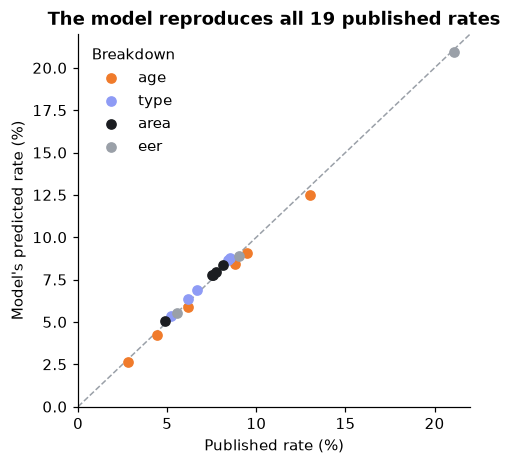

{'mae_pts': 0.2, 'baseline_mae_pts': 1.7, 'correlation': 0.998, 'categories': 19}


In [6]:
fit = model.fit_report.assign(published=lambda d: 100 * d.target, model=lambda d: 100 * d.predicted)
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 22], [0, 22], color=GREY, lw=1, ls="--")
for f, c in zip(FEATURES, [ORANGE, PERIWINKLE, INK, GREY], strict=True):
    s = fit[fit.feature == f]
    ax.scatter(s.published, s.model, label=f, color=c, s=36, zorder=3)
ax.set(xlabel="Published rate (%)", ylabel="Model's predicted rate (%)", xlim=(0, 22), ylim=(0, 22))
ax.set_title("The model reproduces all 19 published rates")
ax.legend(frameon=False, title="Breakdown")
plt.show()
print(summarise(model.fit_report, overall))

### What the model learned

Each coefficient, turned into an **odds ratio**: how much a characteristic multiplies the odds of damp relative to a
typical home, holding the others fixed. Categories with no published rate (e.g. detached social homes, which the survey
suppresses) are fixed at 1× rather than given an invented effect.

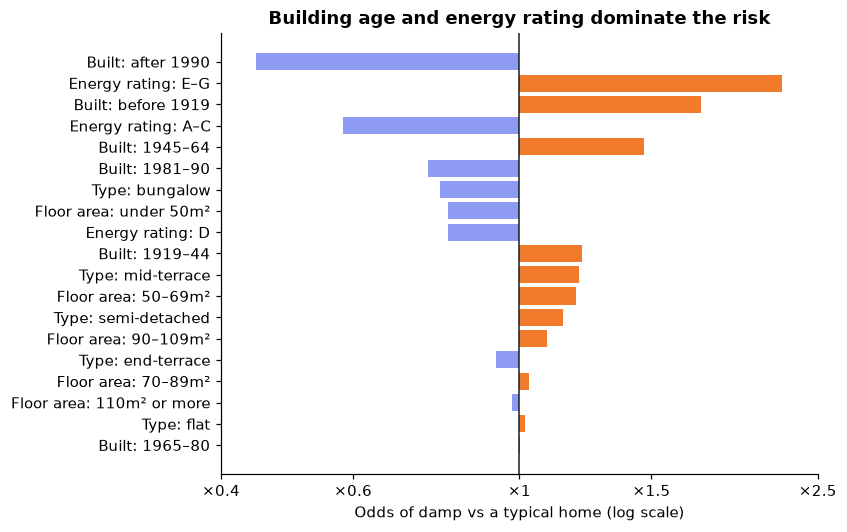

In [7]:
from src.dashboard.data import CATEGORY_LABELS, FEATURE_LABELS

eff = pd.DataFrame([{"effect": f"{FEATURE_LABELS[f]}: {CATEGORY_LABELS.get(c, c)}", "odds_ratio": np.exp(b)}
                    for f, cs in model.coefs.items() for c, b in cs.items() if c in fitted.get(f, {})])
eff = eff.reindex(eff.odds_ratio.apply(lambda v: abs(np.log(v))).sort_values().index)
fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(eff.effect, np.log(eff.odds_ratio), color=[ORANGE if v > 1 else PERIWINKLE for v in eff.odds_ratio])
ticks = [0.4, 0.6, 1, 1.5, 2.5]
ax.set_xticks(np.log(ticks), [f"×{t}" for t in ticks])
ax.axvline(0, color=INK, lw=1)
ax.set_title("Building age and energy rating dominate the risk")
ax.set_xlabel("Odds of damp vs a typical home (log scale)")
plt.show()

### The double-counting check

For the riskiest combination (pre-1919, rated E–G), compare the calibrated model with simply multiplying the published
ratios.

In [8]:
naive = overall * np.prod([cells[f].map(fitted[f]).fillna(overall) / overall for f in FEATURES], axis=0)
worst = (cells.age == "pre1919") & (cells.eer == "E-G")
print(f"Pre-1919, rated E–G ({cells.n[worst].sum():,} homes):")
print(f"  multiplying published ratios: {100 * np.average(naive[worst], weights=cells.n[worst]):.1f}%")
print(f"  calibrated model:             {100 * np.average(p_cells[worst], weights=cells.n[worst]):.1f}%")

Pre-1919, rated E–G (23,178 homes):
  multiplying published ratios: 42.2%
  calibrated model:             27.4%


## 4. Validation

There are no labelled homes, so the model is tested on **published rates it never saw**:

- **Leave one out:** refit without one breakdown (e.g. building age), then predict that breakdown.
- **Never-seen breakdowns:** region and deprivation decile (table DA5102) are never used in fitting.

Each published rate is itself an estimate from a few hundred surveyed social homes. The **noise floor** is the average
error you'd expect from sampling noise alone, even with a perfect model.

In [9]:
import json
val = json.loads((ROOT / "data/processed/model/validation.json").read_text())
rows = [("Fit (19 rates)", val["fit"])] + [(f"Leave out {k}", val[f"leave_out_{k}"]) for k in ["age", "type", "area", "eer"]]
rows += [("Region (never seen)", val["held_out_region"]), ("Deprivation decile (never seen)", val["held_out_imd_decile"])]
pd.DataFrame([{"check": n, "model error (pts)": v["mae_pts"], "baseline (pts)": v["baseline_mae_pts"],
               "noise floor (pts)": v.get("noise_floor_mae_pts", "")} for n, v in rows]).set_index("check")

,model error (pts),baseline (pts),noise floor (pts)
check,,,
Fit (19 rates),0.20,1.70,
Leave out age,1.83,2.60,
Leave out type,0.45,1.08,
Leave out area,0.87,1.04,
Leave out eer,1.42,2.08,
Region (never seen),1.59,1.55,1.0
Deprivation decile (never seen),1.01,0.98,1.03


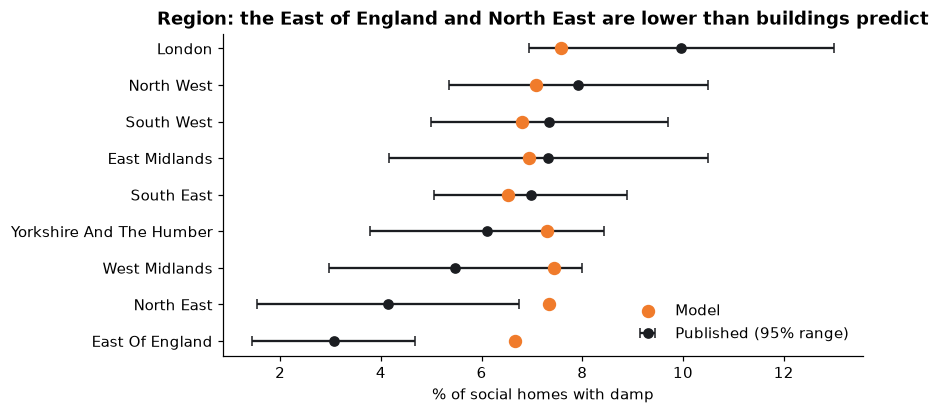

In [10]:
from src.models.fit_damp import OVERLAP_FACTOR, RATES, REGION_MAP, SOCIAL_SAMPLE_SHARE

reg = margin_table(p_cells, cells, {"region": held["region"]})
names = {v: k.title() for k, v in REGION_MAP.items()}
r = pd.read_parquet(RATES)
n_all = (r[(r.table == "DA5102") & (r.breakdown == "government office region") & r.year.isin([2023, 2024])]
         .groupby("category").sample_all_tenures.mean())
reg["name"] = reg.category.map(names)
reg["se"] = [np.sqrt(t * (1 - t) / (n_all[n.lower()] * SOCIAL_SAMPLE_SHARE * OVERLAP_FACTOR))
             for t, n in zip(reg.target, reg.name, strict=True)]
reg = reg.sort_values("target")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(reg))
ax.errorbar(100 * reg.target, y, xerr=196 * reg.se, fmt="o", color=INK, capsize=3, label="Published (95% range)")
ax.scatter(100 * reg.predicted, y, color=ORANGE, s=60, zorder=3, label="Model")
ax.set_yticks(y, reg.name)
ax.set_xlabel("% of social homes with damp")
ax.set_title("Region: the East of England and North East are lower than buildings predict")
ax.legend(frameon=False, loc="lower right")
plt.show()

**Reading the validation:**
- Every **leave-one-out** check beats the baseline, so the breakdowns are mutually consistent and the model captures real
  structure.
- For **deprivation**, the model's error equals the noise floor: the published figures can't tell it apart from a perfect
  model.
- For **region**, most published rates are consistent with the model once sampling noise is allowed for (ranges are
  approximate and, because they ignore the survey's design effect, if anything too narrow). London's higher rate is within
  its range. But the **East of England and North East** are lower than the model predicts beyond noise: something other
  than building characteristics, such as climate, occupancy or maintenance, keeps damp down there. That isn't in the EPC,
  and it's the clearest limit of a buildings-only model.

## 5. Scoring every home, and what it means for targeting

2,855,846 homes · mean 7.1% · expected cases 202,688


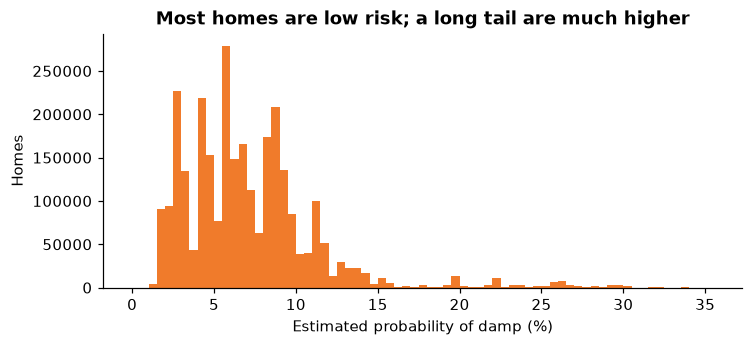

In [11]:
scored = duckdb.sql(f"select risk, msoa21cd from read_parquet('{(ROOT / 'data/processed/epc_scored.parquet').as_posix()}')").df()
print(f"{len(scored):,} homes · mean {100 * scored.risk.mean():.1f}% · "
      f"expected cases {scored.risk.sum():,.0f}")
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.hist(100 * scored.risk, bins=np.arange(0, 36, 0.5), color=ORANGE)
ax.set(xlabel="Estimated probability of damp (%)", ylabel="Homes")
ax.set_title("Most homes are low risk; a long tail are much higher")
plt.show()

### Targeting: homes or places?

If a landlord inspected homes in order of estimated risk, what share of damp cases would they find? Compare ranking
**individual homes** with ranking **whole neighbourhoods** (MSOAs), against inspecting at random.

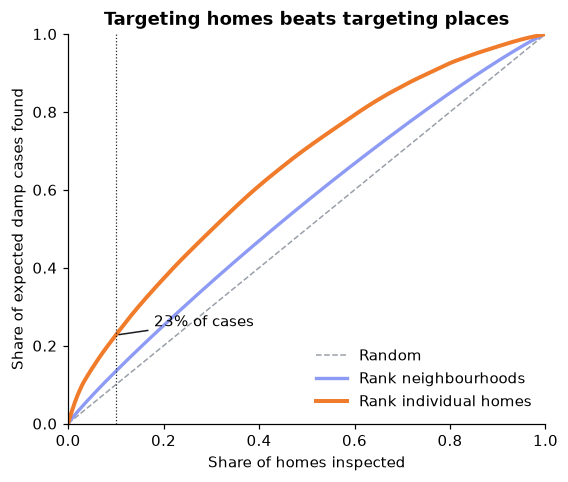

Inspecting the riskiest 10%: homes 22.7% of cases · neighbourhoods 13.4% · random 10%


In [12]:
def gain_curve(risk_sorted):
    cum = np.cumsum(risk_sorted) / risk_sorted.sum()
    return np.linspace(0, 1, len(cum)), cum

homes_x, homes_y = gain_curve(np.sort(scored.risk.to_numpy())[::-1])
areas = scored.groupby("msoa21cd").risk.agg(["sum", "size", "mean"]).sort_values("mean", ascending=False)
areas_x = np.cumsum(areas["size"]) / areas["size"].sum()
areas_y = np.cumsum(areas["sum"]) / areas["sum"].sum()

fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Random")
ax.plot(areas_x, areas_y, color=PERIWINKLE, lw=2.2, label="Rank neighbourhoods")
ax.plot(homes_x, homes_y, color=ORANGE, lw=2.6, label="Rank individual homes")
ax.axvline(0.1, color=INK, lw=0.8, ls=":")
at = lambda x, y: float(np.interp(0.1, x, y))
ax.annotate(f"{100 * at(homes_x, homes_y):.0f}% of cases", (0.1, at(homes_x, homes_y)), xytext=(0.18, 0.25),
            arrowprops={"arrowstyle": "-", "color": INK})
ax.set(xlabel="Share of homes inspected", ylabel="Share of expected damp cases found", xlim=(0, 1), ylim=(0, 1))
ax.set_title("Targeting homes beats targeting places")
ax.legend(frameon=False, loc="lower right")
fig.savefig(ROOT / "reports/figures/targeting_gain_curve.png", bbox_inches="tight", dpi=150)
plt.show()
print(f"Inspecting the riskiest 10%: homes {100 * at(homes_x, homes_y):.1f}% of cases · "
      f"neighbourhoods {100 * at(areas_x, areas_y):.1f}% · random 10%")

## 6. Limitations and next steps

- **Building characteristics only.** Occupancy, heating habits, overcrowding, leaks and repairs drive damp too, and the
  regional check shows they matter.
- **Calibrated to averages.** Effects are assumed to add on the log-odds scale (no interactions); survey and EPC
  categories are matched approximately; the energy-rating rates are derived from report figures.
- **The gain curve is the model's own expectation**, not observed outcomes. With home-level outcomes (survey microdata, or a
  landlord's inspection records) it could be tested directly; the evaluation toolkit in `src/models/` is ready for that.
- **Next:** uncertainty ranges via a bootstrap over the published rates' sampling error, and overcrowding (Census 2021) and
  climate data to address the regional gap.